# Spinner rotation speed from events

How fast is the fidget spinner turning, measured from events alone, by two independent methods: contrast maximization with an in-plane rotation (notebooks 02 and 05) and the event-rate spectrum (notebook 04). Data: DAVIS346 recordings of a 3-arm spinner lying flat, camera fixed; each starts with the spinner held still, then a flick (the hand is in view) and the spin-down.

## Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    sys.path.insert(0, REPO)
else:
    # local: assumes `pip install -e .` was run from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

from evcam.sources import load_davis
from evcam.cmax import cmax_rotation_2d, iwe_from_coords, rotation_warp_2d
from evcam.frequency import event_rate_spectrum, SNR_MIN

T_NOTEBOOK = time.time()

## 0. Parameters

`T_START_S`: start of the analysis, after the flick once the hand is out of view (section 1 shows where); `None` uses `T_START_DEFAULTS` for the file. `CENTER`, `RADIUS_PX`, `RING_ROI`: `None` = estimated. `GT_POINTS`: optional `(t_s, rev_per_s)` measured by hand from the phone video (rev/s = 240 / frames per revolution), plotted in section 5.

In [3]:
RECORDING = "data/davis_data/spinner2.aedat4"    # any spinner file works
N_ARMS = 3
T_START_DEFAULTS = {"spinner1.aedat4": 3.6, "spinner2.aedat4": 3.4, "spinner3.aedat4": 3.0}
T_START_S = None          # s; None = T_START_DEFAULTS[file name] if listed
T_END_S = None            # s; None = end of recording
CENTER = None             # (x, y) px; None = estimated
RADIUS_PX = None          # px; None = estimated
CMAX_WINDOW_MS = 40
MAX_REV_S = 15            # CMax searches |omega| <= MAX_REV_S; the FFT searches up to N_ARMS * MAX_REV_S
FFT_WINDOW_S = 2.0
STEP_S = 0.25
RING_ROI = None           # (x0, y0, x1, y1); None = automatic radial strip
GT_POINTS = []            # [(t_s, rev_per_s), ...]

## 1. Recording overview

Event rate over the whole recording and one APS frame. Pick `T_START_S` just after the flick once the hand has left the view: the event rate jumps at the flick and decays during the spin-down.

source davis, 346x260, 284 frames over 10.851 s, 26.0817 fps, 1,293,365 events over 10.890 s


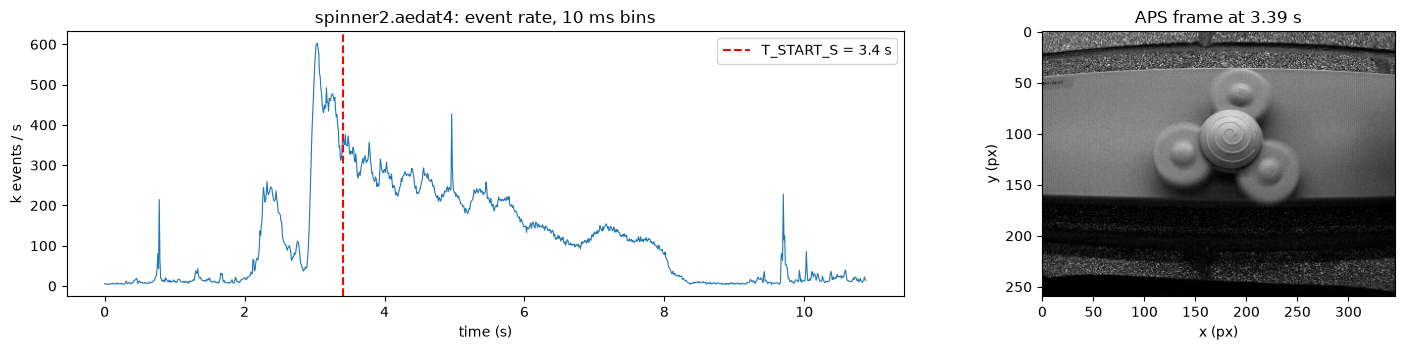

In [4]:
clip = load_davis(RECORDING)
ev, (H, W) = clip.events, clip.shape
name = os.path.basename(RECORDING)
if T_START_S is None:
    T_START_S = T_START_DEFAULTS.get(name)
t_end_s = ev["t"][-1] / 1e6 if T_END_S is None else T_END_S
print(clip.summary())

edges = np.arange(0, ev["t"][-1] + 10_000, 10_000)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(edges[:-1] / 1e6, np.histogram(ev["t"], edges)[0] / 10, lw=0.8)       # per 10 ms -> k events / s
if T_START_S is not None:
    ax[0].axvline(T_START_S, color="r", ls="--", label=f"T_START_S = {T_START_S} s"); ax[0].legend()
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("k events / s"); ax[0].set_title(f"{name}: event rate, 10 ms bins")
k_frame = 0 if (clip.frames is None or T_START_S is None) else int(np.argmin(np.abs(clip.frame_t / 1e6 - T_START_S)))
if clip.frames is not None:
    ax[1].imshow(clip.frames[k_frame], cmap="gray"); ax[1].set_title(f"APS frame at {clip.frame_t[k_frame] / 1e6:.2f} s")
ax[1].set_xlabel("x (px)"); ax[1].set_ylabel("y (px)")
plt.tight_layout(); plt.show()

if T_START_S is None:
    raise RuntimeError(f"Set T_START_S in section 0 (no default for {name}): just after the flick, once the hand is out of view.")

## 2. Geometry

The arms sweep a disk symmetric about the hub, so the center is the centroid of the event count image over the first 0.5 s after `T_START_S`, and the radius the 95th percentile of the event distances from it. Uniform background events and reflections below the spinner pull a plain centroid off, so both use only pixels above half the 99th percentile of the count image. Only events inside 1.1 × radius are used from here on.

center (185.4, 130.0) px, radius 64.7 px


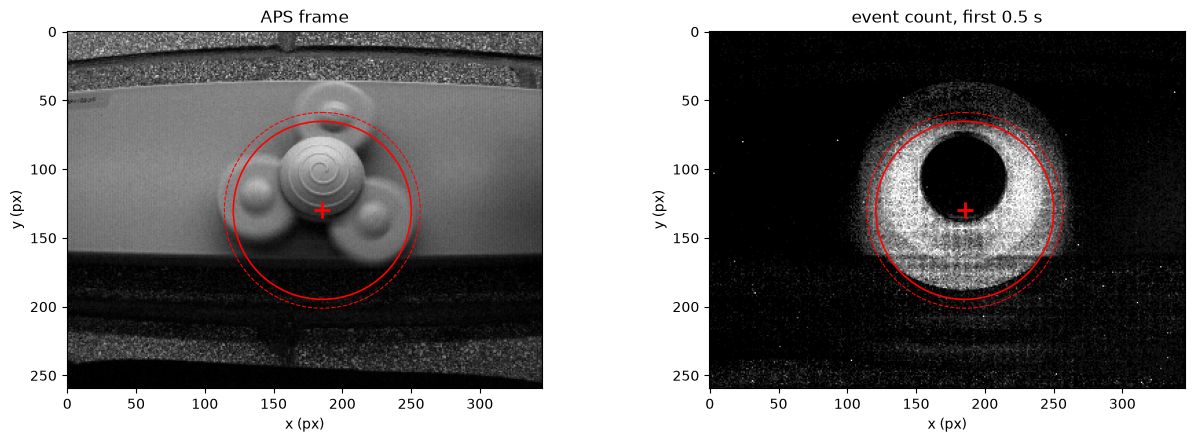

In [5]:
t0_us = int(T_START_S * 1e6)
first = ev[(ev["t"] >= t0_us) & (ev["t"] < t0_us + 500_000)]
count = np.bincount(first["y"].astype(np.int64) * W + first["x"], minlength=H * W).reshape(H, W).astype(float)
busy = count >= 0.5 * np.percentile(count, 99)
yy, xx = np.mgrid[:H, :W]
center = CENTER or (float((count * busy * xx).sum() / (count * busy).sum()), float((count * busy * yy).sum() / (count * busy).sum()))
on_busy = busy[first["y"], first["x"]]
radius = RADIUS_PX or float(np.percentile(np.hypot(first["x"][on_busy] - center[0], first["y"][on_busy] - center[1]), 95))
print(f"center ({center[0]:.1f}, {center[1]:.1f}) px, radius {radius:.1f} px")

r_ev = np.hypot(ev["x"] - center[0], ev["y"] - center[1])
disk = ev[(r_ev < 1.1 * radius) & (ev["t"] >= t0_us) & (ev["t"] < t_end_s * 1e6)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
if clip.frames is not None:
    ax[0].imshow(clip.frames[k_frame], cmap="gray"); ax[0].set_title("APS frame")
ax[1].imshow(count, cmap="gray", vmax=np.percentile(count, 99.5)); ax[1].set_title("event count, first 0.5 s")
for a in ax:
    a.plot(*center, "r+", ms=12, mew=2)
    a.add_patch(plt.Circle(center, radius, fill=False, ec="r", lw=1.2))
    a.add_patch(plt.Circle(center, 1.1 * radius, fill=False, ec="r", lw=0.8, ls="--"))
    a.set_xlabel("x (px)"); a.set_ylabel("y (px)")
plt.tight_layout(); plt.show()

## 3. Rotation speed by contrast maximization

In-plane rotation about the center $\mathbf{c}$ with constant angular velocity $\omega$ inside a short window, warped with `cmax_rotation_2d` (`evcam/cmax.py`):

$$\mathbf{x}'_k = \mathbf{c} + R\big(-\omega\,(t_k - t_\text{ref})\big)\,(\mathbf{x}_k - \mathbf{c}), \qquad \omega^* = \arg\max_\omega \operatorname{Var}\big(H(\mathbf{x};\omega)\big)$$

$R(a)$: rotation by angle $a$, $t_\text{ref}$: window midpoint, $H$: image of warped events, as in notebooks 02 and 05. The contrast is evaluated on a grid over $|\omega| \le$ `MAX_REV_S` (both directions, $\omega > 0$ is clockwise on screen) and the best point is refined by a bounded scalar search.

The 3 arms are identical, so a rotation by 1/`N_ARMS` of a turn maps the pattern onto itself, and a window longer than that gives the contrast extra peaks. The window is kept well under $1/(N_\text{arms} \cdot \text{rev/s})$: 40 ms is under 1/3 revolution up to about 8 rev/s, above the fastest spin here; shorter windows hold fewer events and give a broader peak.

window at 3.50 s: 10,253 events, omega = 7.86 rad/s = +1.25 rev/s


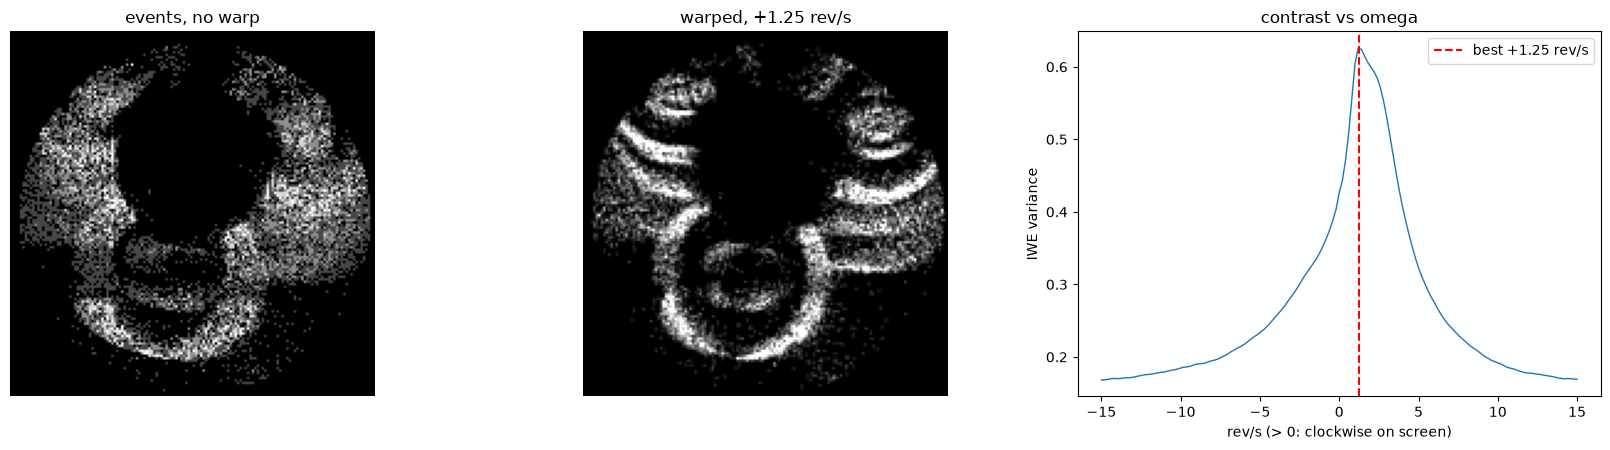

In [6]:
win_us = CMAX_WINDOW_MS * 1000
omegas = 2 * np.pi * np.arange(-MAX_REV_S, MAX_REV_S + 1e-9, 0.2)      # rad/s, 0.2 rev/s grid


def cmax_window(t_a_us):
    w = disk[(disk["t"] >= t_a_us) & (disk["t"] < t_a_us + win_us)]
    if len(w) < 500:
        return None
    x, y, t = w["x"].astype(float), w["y"].astype(float), (w["t"] - t_a_us) / 1e6
    omega, con = cmax_rotation_2d(x, y, t, center, win_us / 2e6, omegas)
    return omega, con, (x, y, t)


t_a = int((T_START_S + 0.1) * 1e6)                # one window early in the spin
omega, con, (x, y, t) = cmax_window(t_a)
img0 = iwe_from_coords(x, y, (H, W), sigma=0)
img1 = iwe_from_coords(*rotation_warp_2d(x, y, t, omega, center, win_us / 2e6), (H, W), sigma=0)
vmax = np.percentile(img1, 99.5)
print(f"window at {t_a / 1e6:.2f} s: {len(x):,} events, omega = {omega:.2f} rad/s = {omega / (2 * np.pi):+.2f} rev/s")

r = int(1.15 * radius)
box = (slice(max(int(center[1]) - r, 0), int(center[1]) + r), slice(max(int(center[0]) - r, 0), int(center[0]) + r))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].imshow(img0[box], cmap="gray", vmin=0, vmax=vmax); ax[0].set_title("events, no warp")
ax[1].imshow(img1[box], cmap="gray", vmin=0, vmax=vmax); ax[1].set_title(f"warped, {omega / (2 * np.pi):+.2f} rev/s")
for a in ax[:2]: a.axis("off")
ax[2].plot(omegas / (2 * np.pi), con, lw=1)
ax[2].axvline(omega / (2 * np.pi), color="r", ls="--", label=f"best {omega / (2 * np.pi):+.2f} rev/s")
ax[2].set_xlabel("rev/s (> 0: clockwise on screen)"); ax[2].set_ylabel("IWE variance"); ax[2].set_title("contrast vs omega")
ax[2].legend(); plt.tight_layout(); plt.show()

Rotation speed for windows every `STEP_S` from `T_START_S` to the end (windows with fewer than 500 events are left out).

20 windows in 1 s, 1.24 down to 0.00 rev/s


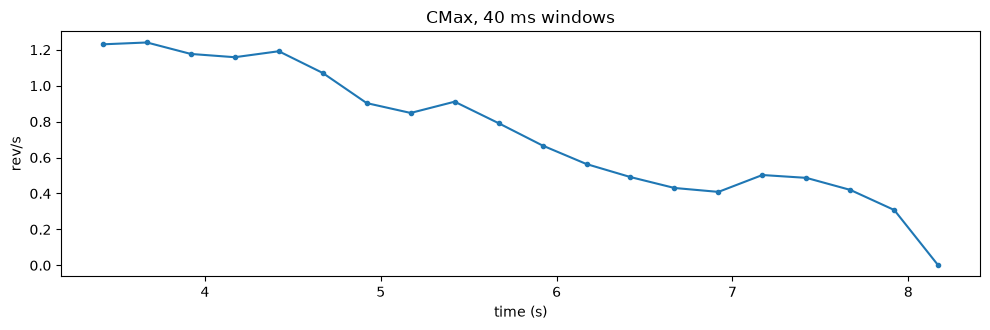

In [7]:
tic = time.time()
cmax_t, cmax_rev = [], []
for ts in np.arange(T_START_S, t_end_s - CMAX_WINDOW_MS / 1e3, STEP_S):
    res = cmax_window(int(ts * 1e6))
    if res is not None:
        cmax_t.append(ts + CMAX_WINDOW_MS / 2e3); cmax_rev.append(abs(res[0]) / (2 * np.pi))
cmax_t, cmax_rev = np.array(cmax_t), np.array(cmax_rev)
print(f"{len(cmax_t)} windows in {time.time() - tic:.0f} s, {cmax_rev.max():.2f} down to {cmax_rev.min():.2f} rev/s")

plt.figure(figsize=(10, 3.4))
plt.plot(cmax_t, cmax_rev, "o-", ms=3)
plt.xlabel("time (s)"); plt.ylabel("rev/s"); plt.title(f"CMax, {CMAX_WINDOW_MS} ms windows"); plt.tight_layout(); plt.show()

## 4. Rotation speed from the event rate (FFT)

The method of notebook 04 through `evcam.frequency`: the ON events in a small ROI that the arms sweep through pulse once per passing arm, so the event-rate spectrum peaks at the arm-passing frequency $f_\text{arm} = N_\text{arms} \cdot \text{rev/s}$. The ROI must be small: a large ROI always contains some arm, so its event rate barely varies. The automatic `RING_ROI` is a radial strip 3 px wide from 0.3 to 1.0 × radius, right of the center. Windows are `FFT_WINDOW_S` long every `STEP_S`, short because the spinner slows down and the FFT assumes a constant frequency in the window, with a 1 Hz minimum frequency.

Each lobe has several rings, so a passing lobe gives several pulses and the plain spectrum peak locks onto a harmonic of $f_\text{arm}$. The harmonic product spectrum (Noll 1969) multiplies the spectrum by copies compressed by 2 and 3, so only the fundamental, where the harmonics line up, stays large:

$$P_\text{HPS}(f) = \prod_{k=1}^{3} P(k f), \qquad \hat f_\text{arm} = \arg\max_{1\,\text{Hz} \le f \le N_\text{arms} \cdot \text{MAX\_REV\_S}} P_\text{HPS}(f)$$

The peak is refined between bins with a parabola through the log of $P_\text{HPS}$, as in `event_rate_spectrum`. At a few Hz a 2 s window has too few bins for the local peak ratio of notebook 04, so a window counts as detected if the HPS peak is at least `SNR_MIN`$^3$ times the median of $P_\text{HPS}$ over the search band (cubed because it is a product of 3 spectra).

ROI (205, 129, 250, 132); window 3.40 to 5.40 s: plain peak 13.46 Hz, HPS peak 3.43 Hz (peak / median 6.2e+06) -> 1.14 rev/s


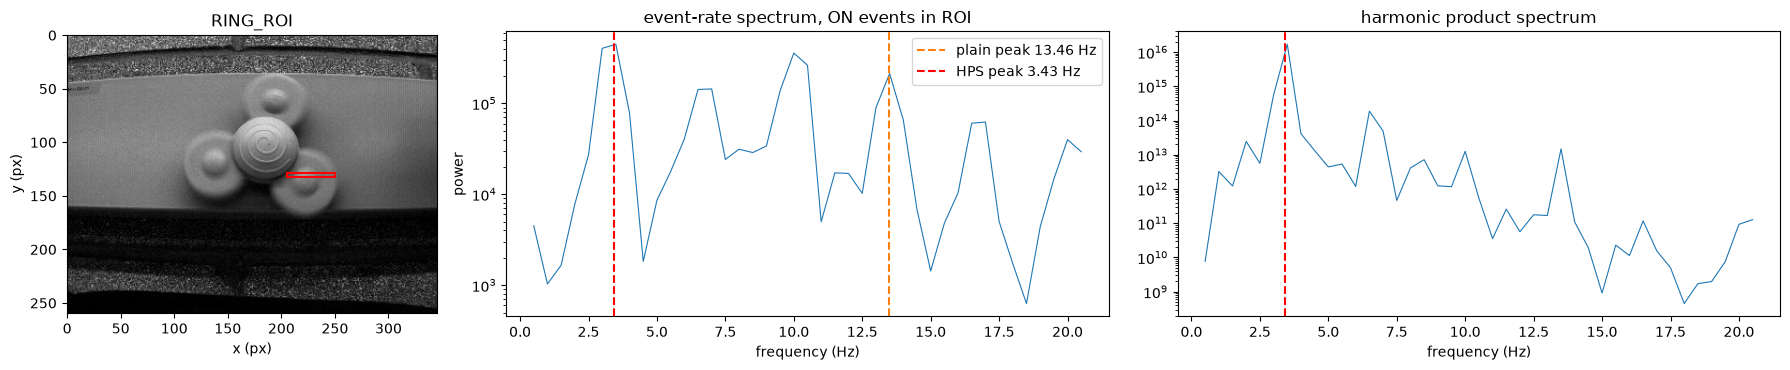

In [8]:
BIN_US = 1000
roi = RING_ROI or (int(round(center[0] + 0.3 * radius)), int(round(center[1])) - 1,
                   int(round(center[0] + radius)), int(round(center[1])) + 2)


def hps_peak(freqs, power, n_harm=3, f_min=1.0, f_max=None):
    # harmonic product spectrum: peak frequency (parabolic refinement) and peak / median over the search band
    n = len(power) // n_harm
    prod = np.prod([power[::k][:n] for k in range(1, n_harm + 1)], axis=0)
    f = freqs[:n]
    ok = np.flatnonzero((f >= f_min) & (f <= (f_max or f[-1])))
    k = ok[np.argmax(prod[ok])]
    f_hat = f[k]
    if 0 < k < n - 1:
        a, b, c = np.log(prod[k - 1:k + 2] + 1e-300)
        f_hat += np.clip(0.5 * (a - c) / (a - 2 * b + c), -0.5, 0.5) * (f[1] - f[0])
    return f_hat, prod[k] / np.median(prod[ok]), f, prod


def fft_window(t_a_us):
    freqs, power, f_plain = event_rate_spectrum(ev, t_a_us, t_a_us + int(FFT_WINDOW_S * 1e6), bin_us=BIN_US,
                                                roi=roi, polarity=1, f_min=1.0)
    f_hps, ratio, f, prod = hps_peak(freqs, power, f_max=N_ARMS * MAX_REV_S)
    return freqs, power, f_plain, f_hps, ratio, f, prod


freqs, power, f_plain, f_hps, ratio, f, prod = fft_window(t0_us)
print(f"ROI {roi}; window {T_START_S:.2f} to {T_START_S + FFT_WINDOW_S:.2f} s: plain peak {f_plain:.2f} Hz, "
      f"HPS peak {f_hps:.2f} Hz (peak / median {ratio:.1e}) -> {f_hps / N_ARMS:.2f} rev/s")

fig, ax = plt.subplots(1, 3, figsize=(18, 3.8), gridspec_kw={"width_ratios": [0.8, 1.3, 1.3]})
if clip.frames is not None:
    ax[0].imshow(clip.frames[k_frame], cmap="gray")
ax[0].add_patch(plt.Rectangle((roi[0], roi[1]), roi[2] - roi[0], roi[3] - roi[1], fill=False, ec="r", lw=1.5))
ax[0].set_title("RING_ROI"); ax[0].set_xlabel("x (px)"); ax[0].set_ylabel("y (px)")
fmax = 6 * f_hps
sel = (freqs > 0) & (freqs <= fmax)
ax[1].semilogy(freqs[sel], power[sel], lw=0.8)
ax[1].axvline(f_plain, color="tab:orange", ls="--", label=f"plain peak {f_plain:.2f} Hz")
ax[1].axvline(f_hps, color="r", ls="--", label=f"HPS peak {f_hps:.2f} Hz")
ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("power"); ax[1].set_title("event-rate spectrum, ON events in ROI"); ax[1].legend()
sel = (f > 0) & (f <= fmax)
ax[2].semilogy(f[sel], prod[sel], lw=0.8); ax[2].axvline(f_hps, color="r", ls="--")
ax[2].set_xlabel("frequency (Hz)"); ax[2].set_title("harmonic product spectrum")
plt.tight_layout(); plt.show()

15 of 22 windows with a detected peak (7 left out), 1.14 down to 0.42 rev/s


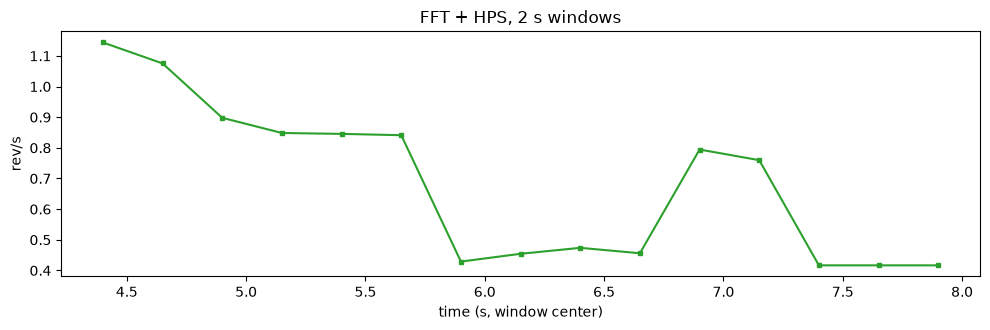

In [9]:
fft_t, fft_rev, missed = [], [], 0
for ts in np.arange(T_START_S, t_end_s - FFT_WINDOW_S, STEP_S):
    _, _, _, f_hps, ratio, _, _ = fft_window(int(ts * 1e6))
    if ratio >= SNR_MIN ** 3:
        fft_t.append(ts + FFT_WINDOW_S / 2); fft_rev.append(f_hps / N_ARMS)
    else:
        missed += 1
fft_t, fft_rev = np.array(fft_t), np.array(fft_rev)
print(f"{len(fft_t)} of {len(fft_t) + missed} windows with a detected peak ({missed} left out)"
      + (f", {fft_rev.max():.2f} down to {fft_rev.min():.2f} rev/s" if len(fft_t) else ""))

plt.figure(figsize=(10, 3.4))
plt.plot(fft_t, fft_rev, "s-", ms=3, color="tab:green")
plt.xlabel("time (s, window center)"); plt.ylabel("rev/s"); plt.title(f"FFT + HPS, {FFT_WINDOW_S:g} s windows")
plt.tight_layout(); plt.show()

## 5. Comparison

Each FFT value is compared with the median of the CMax values inside its window; the FFT value is an average over `FFT_WINDOW_S`, so it lags the CMax curve while the spinner slows down.

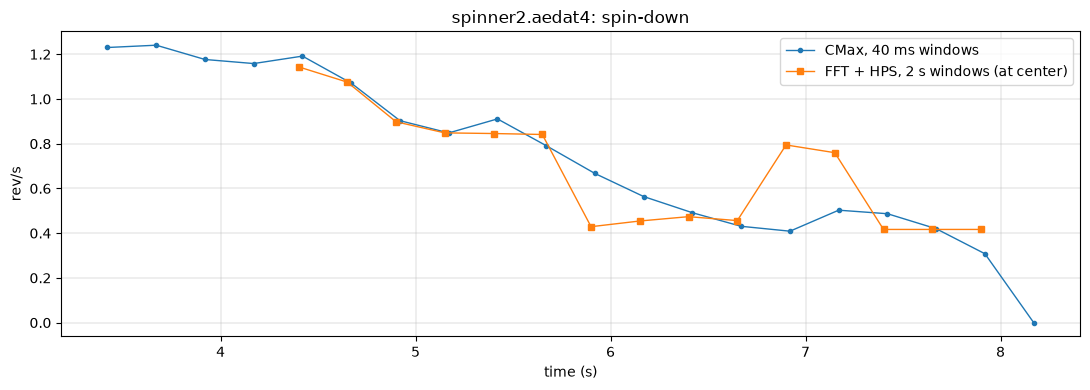

median relative difference FFT vs CMax: 6.4% over 15 windows
notebook runtime 2 s


In [10]:
plt.figure(figsize=(11, 4))
plt.plot(cmax_t, cmax_rev, "o-", ms=3, lw=1, label=f"CMax, {CMAX_WINDOW_MS} ms windows")
plt.plot(fft_t, fft_rev, "s-", ms=4, lw=1, label=f"FFT + HPS, {FFT_WINDOW_S:g} s windows (at center)")
if GT_POINTS:
    plt.plot(*zip(*GT_POINTS), "k*", ms=10, label="phone video (by hand)")
plt.xlabel("time (s)"); plt.ylabel("rev/s"); plt.title(f"{name}: spin-down"); plt.legend(); plt.grid(lw=0.3)
plt.tight_layout(); plt.show()

rel = []
for tc, rf in zip(fft_t, fft_rev):
    inside = np.abs(cmax_t - tc) <= FFT_WINDOW_S / 2
    if inside.any():
        ref = np.median(cmax_rev[inside])
        rel.append(abs(rf - ref) / ref)
print(f"median relative difference FFT vs CMax: {np.median(rel):.1%} over {len(rel)} windows")
print(f"notebook runtime {time.time() - T_NOTEBOOK:.0f} s")

## References

1. G. Gallego, H. Rebecq, D. Scaramuzza, "A Unifying Contrast Maximization Framework for Event Cameras, with Applications to Motion, Depth, and Optical Flow Estimation", CVPR 2018.
2. G. Gallego, D. Scaramuzza, "Accurate Angular Velocity Estimation With an Event Camera", IEEE Robotics and Automation Letters 2(2), 2017.
3. A. M. Noll, "Pitch Determination of Human Speech by the Harmonic Product Spectrum, the Harmonic Sum Spectrum, and a Maximum Likelihood Estimate", Symposium on Computer Processing in Communications, Brooklyn, April 1969; Proceedings vol. XIX, Polytechnic Press, 1970, pp. 779-797.

The event-rate spectrum is the method of notebook 04.